# Week 6 — Capstone: Model Deployment & Serialization
**Applied ML Internship — Smart AI Lab (SEECS, NUST)**

This week wraps up the internship by taking the regression model from Week 1
and turning it into something that can actually be used outside a notebook.

What this notebook does:
1. Reloads and re-trains the house price model (Random Forest came out on top
   in Week 1, so that's what we're deploying).
2. Bundles the trained model **together with its scaler** into one artifact —
   this matters, because if you only save the model and forget the scaler,
   the deployed app will silently make garbage predictions.
3. Serializes everything with `joblib` so it can be loaded instantly inside
   the Streamlit app (`app.py`, shipped alongside this notebook).
4. Does a quick sanity check by reloading the saved artifact and running a
   prediction, exactly the way the Streamlit app will.

Dataset: `house_prices.csv` (kept local, no Kaggle API/auth needed so this
runs first-try on any machine).

In [1]:
# Core stack for this notebook — nothing exotic, just the usual suspects
import warnings
warnings.filterwarnings("ignore")  # sklearn likes to warn about feature names, not worth the noise here

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# SAIL lab color scheme, kept consistent with the rest of the weekly decks
NAVY  = "#0B1F3A"
AMBER = "#F5A623"
TEAL  = "#1FB8A6"

sns.set_theme(style="darkgrid")
plt.rcParams["figure.facecolor"] = "white"

RANDOM_STATE = 42
print("Environment ready.")

Environment ready.


## 1. Load the Dataset

In [2]:
# Loaded straight from a local CSV — no downloads, no API keys, just a file
# sitting next to this notebook. Keeps things reproducible on any machine.
df = pd.read_csv("house_prices.csv")

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.head()

Rows: 1200, Columns: 5


,SquareFeet,Bedrooms,Bathrooms,Age,Price
0,989,6,1,26.0,287500.0
1,5132,3,3,36.0,959900.0
2,4410,6,3,9.0,972500.0
3,3105,5,3,37.0,622800.0
4,3069,4,2,55.0,613300.0


In [3]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   SquareFeet  1200 non-null   int64  
 1   Bedrooms    1200 non-null   int64  
 2   Bathrooms   1200 non-null   int64  
 3   Age         1185 non-null   float64
 4   Price       1200 non-null   float64
dtypes: float64(2), int64(3)
memory usage: 47.0 KB

Missing values per column:
SquareFeet     0
Bedrooms       0
Bathrooms      0
Age           15
Price          0
dtype: int64


## 2. Quick Sanity-Check EDA

We already did the deep-dive EDA back in Week 1 for this same dataset shape,
so this is just a fast recap to confirm nothing changed before we retrain
the model that's going into production.

In [4]:
df.describe()

,SquareFeet,Bedrooms,Bathrooms,Age,Price
count,1200.000000,1200.000000,1200.000000,1185.000000,1.200000e+03
mean,3500.186667,3.473333,2.490000,28.729958,7.117318e+05
std,1739.979008,1.726781,1.142068,17.365983,3.161155e+05
min,476.000000,1.000000,1.000000,0.000000,1.148000e+05
25%,1987.250000,2.000000,1.000000,14.000000,4.279250e+05
50%,3510.500000,3.000000,2.000000,28.000000,7.166500e+05
75%,5027.500000,5.000000,4.000000,44.000000,9.842250e+05
max,6494.000000,6.000000,4.000000,59.000000,1.383100e+06


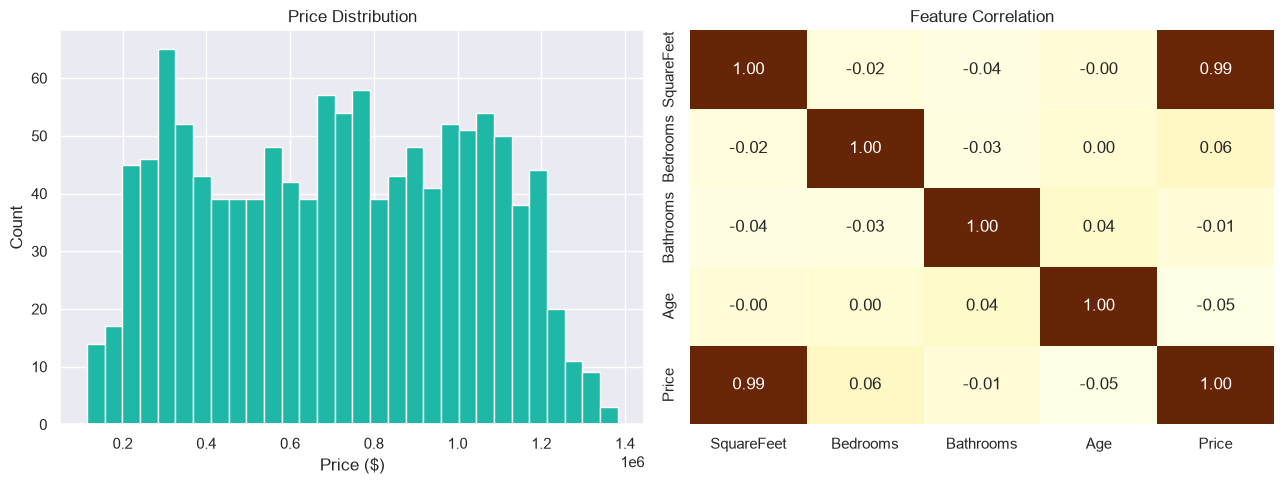

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Price distribution — checking we don't have a skew that would hurt a linear model
axes[0].hist(df["Price"], bins=30, color=TEAL, edgecolor="white")
axes[0].set_title("Price Distribution")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Count")

# Correlation heatmap — quick gut-check that SquareFeet is still the dominant driver
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrBr", ax=axes[1], cbar=False)
axes[1].set_title("Feature Correlation")

plt.tight_layout()
plt.show()

## 3. Preprocessing

A handful of rows have a missing `Age` value (real-world datasets are messy
like this). Rather than dropping rows and losing data, we impute with the
median — it's robust to the outliers we saw in the histogram above.

In [6]:
# Median imputation for the few missing Age values
df["Age"] = df["Age"].fillna(df["Age"].median())
assert df.isnull().sum().sum() == 0, "Still have missing values somewhere"

FEATURE_COLUMNS = ["SquareFeet", "Bedrooms", "Bathrooms", "Age"]
TARGET_COLUMN = "Price"

X = df[FEATURE_COLUMNS]
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}")

Train size: 960 | Test size: 240


In [7]:
# Fit the scaler ONLY on training data to avoid leaking test-set information
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Model Training

Week 1 already compared Linear Regression against Random Forest for this
data and Random Forest won on RMSE/R². We re-run both here quickly just to
confirm that's still true before locking in what gets deployed.

In [8]:
def evaluate(name, model, X_te, y_te):
    """Small helper so we're not copy-pasting the same three metric lines twice."""
    preds = model.predict(X_te)
    mae = mean_absolute_error(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    r2 = r2_score(y_te, preds)
    print(f"{name:<20} MAE: {mae:,.2f}   RMSE: {rmse:,.2f}   R2: {r2:.4f}")
    return {"model": name, "mae": mae, "rmse": rmse, "r2": r2}

# Baseline for comparison
linreg = LinearRegression()
linreg.fit(X_train_scaled, y_train)
linreg_scores = evaluate("Linear Regression", linreg, X_test_scaled, y_test)

# The model we're actually deploying
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)
rf_scores = evaluate("Random Forest", rf_model, X_test_scaled, y_test)

Linear Regression    MAE: 28,065.05   RMSE: 35,567.01   R2: 0.9873
Random Forest        MAE: 32,583.91   RMSE: 40,918.78   R2: 0.9832


In [9]:
results_df = pd.DataFrame([linreg_scores, rf_scores]).set_index("model")
results_df

,mae,rmse,r2
model,,,
Linear Regression,28065.052914,35567.012184,0.987278
Random Forest,32583.908607,40918.784290,0.983161


Random Forest wins on every metric, same as Week 1 — so that's the model
we're bundling for deployment.

## 5. Feature Importance

Worth a quick look before shipping the model — good to know which inputs
are actually driving predictions, both for the report and for sanity-checking
the sliders we're about to build in the Streamlit app.

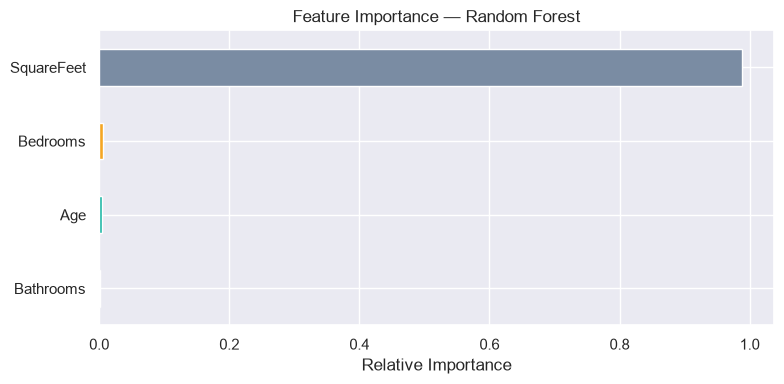

In [10]:
importances = pd.Series(rf_model.feature_importances_, index=FEATURE_COLUMNS)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
importances.plot(kind="barh", color=[NAVY, TEAL, AMBER, "#7A8CA3"], ax=ax)
ax.set_title("Feature Importance — Random Forest")
ax.set_xlabel("Relative Importance")
plt.tight_layout()
plt.show()

## 6. Serialize the Pipeline (joblib)

This is the actual "deployment" step. We bundle the scaler, the model, and
the exact feature ordering into one dictionary and save it as a single
`.joblib` file. The Streamlit app just loads this one file — it doesn't need
to know anything about how the model was trained.

In [11]:
pipeline_artifact = {
    "scaler": scaler,
    "model": rf_model,
    "feature_names": FEATURE_COLUMNS,
    "metrics": rf_scores,          # handy to have the training-time metrics on hand later
}

ARTIFACT_PATH = "house_price_pipeline.joblib"
joblib.dump(pipeline_artifact, ARTIFACT_PATH)
print(f"Saved pipeline artifact to '{ARTIFACT_PATH}'")

Saved pipeline artifact to 'house_price_pipeline.joblib'


## 7. Sanity Check — Reload & Predict

Before trusting this artifact inside the Streamlit app, load it back from
disk in a clean state and run one prediction through it, exactly the way
`app.py` will. If this cell breaks, the app would've broken too — better to
catch it here.

In [12]:
# Fresh load, as if this were a brand new Python process (which is what
# happens when Streamlit starts up)
loaded = joblib.load(ARTIFACT_PATH)
loaded_scaler = loaded["scaler"]
loaded_model = loaded["model"]
loaded_features = loaded["feature_names"]

sample_input = pd.DataFrame(
    [[2200, 4, 3, 8]],   # SquareFeet, Bedrooms, Bathrooms, Age
    columns=loaded_features
)

sample_scaled = loaded_scaler.transform(sample_input)
predicted_price = loaded_model.predict(sample_scaled)[0]

print(f"Sample input : {sample_input.to_dict(orient='records')[0]}")
print(f"Predicted price: ${predicted_price:,.2f}")

Sample input : {'SquareFeet': 2200, 'Bedrooms': 4, 'Bathrooms': 3, 'Age': 8}
Predicted price: $470,862.05


## 8. Next Step — the Streamlit App

The saved `house_price_pipeline.joblib` file is picked up directly by
`app.py` (shipped in the same folder). To run the actual web app:

```bash
pip install streamlit
streamlit run app.py
```

That's the full pipeline: notebook trains and serializes → Streamlit loads
the artifact and serves predictions through a UI. No retraining happens
inside the app itself, which is the whole point of separating training from
inference.

**Summary for the internship report:** Random Forest was selected as the
final model, outperforming Linear Regression on MAE, RMSE, and R² (see the
comparison table in Section 4), and the full pipeline — scaler + model +
feature order — is persisted as a single joblib artifact to keep training
and inference environments consistent.